<a href="https://colab.research.google.com/github/smkanishka/virtual-tryon-visual-matching/blob/feature%2Fvirtual-tryon-prototype/R%26D_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("R&D Virtual Try-On Project")
print("Environment setup successful!")

R&D Virtual Try-On Project
Environment setup successful!


In [ ]:
!pip -q install pillow opencv-python-headless numpy pandas scikit-learn matplotlib

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

print("All libraries imported successfully!")

# Create folders for the project
Path("data/person_images").mkdir(parents=True, exist_ok=True)
Path("data/garment_images").mkdir(parents=True, exist_ok=True)
Path("data/catalog").mkdir(parents=True, exist_ok=True)
Path("outputs/approach1").mkdir(parents=True, exist_ok=True)
Path("outputs/approach2").mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")

All libraries imported successfully!
Project folders created successfully!


In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
from pathlib import Path
from PIL import Image
from IPython.display import display
import shutil

person_folder = Path("data/person_images")
garment_folder = Path("data/garment_images")

for filename in uploaded.keys():
    path = Path(filename)

    try:
        img = Image.open(filename)
        display(img)

        if "person" in filename.lower():
            shutil.copy(filename, person_folder / filename)
            print(filename, "saved as a person image")

        elif "shirt" in filename.lower() or "garment" in filename.lower():
            shutil.copy(filename, garment_folder / filename)
            print(filename, "saved as a garment image")

        else:
            print("Image shown, but filename needs to identify it as person or garment:", filename)

    except Exception as e:
        print("Could not open", filename, ":", e)

In [ ]:
from pathlib import Path

print("Person images:", list(Path("data/person_images").iterdir()))
print("Garment images:", list(Path("data/garment_images").iterdir()))

Person image size: (800, 1173)
Shirt image size: (980, 980)


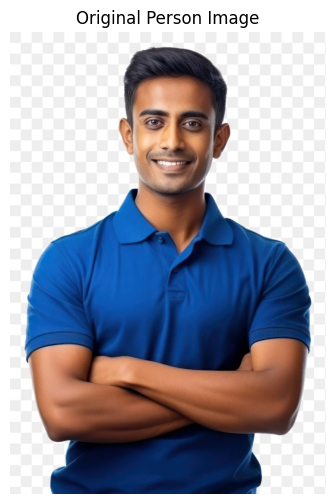

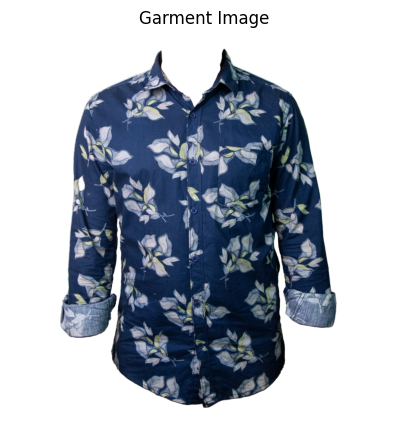

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

person_files = list(Path("data/person_images").glob("*"))
garment_files = list(Path("data/garment_images").glob("*"))

if not person_files or not garment_files:
    print("Person or shirt image is missing. Please check the folders.")
else:
    person = Image.open(person_files[0]).convert("RGB")
    shirt = Image.open(garment_files[0]).convert("RGBA")

    print("Person image size:", person.size)
    print("Shirt image size:", shirt.size)

    plt.figure(figsize=(5, 6))
    plt.imshow(person)
    plt.title("Original Person Image")
    plt.axis("off")
    plt.show()

    plt.figure(figsize=(5, 6))
    plt.imshow(shirt)
    plt.title("Garment Image")
    plt.axis("off")
    plt.show()

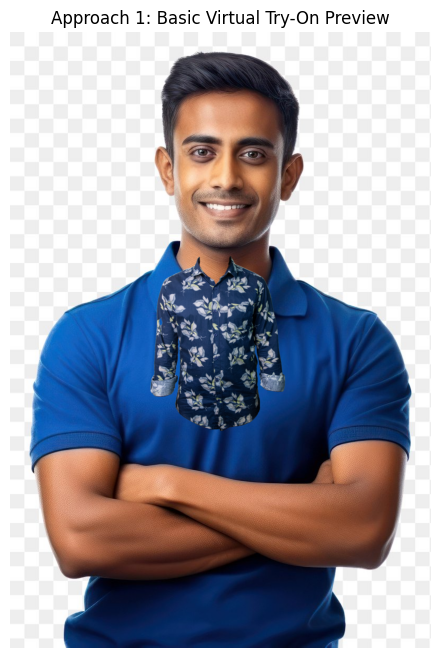

Preview saved to: outputs/approach1/tryon_preview.png


In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Load the images
person_files = list(Path("data/person_images").glob("*"))
garment_files = list(Path("data/garment_images").glob("*"))

person = Image.open(person_files[0]).convert("RGBA")
shirt = Image.open(garment_files[0]).convert("RGBA")

# Resize the shirt to fit the preview
person_width, person_height = person.size
shirt_width = int(person_width * 0.45)
shirt_height = int(shirt.height * shirt_width / shirt.width)

shirt = shirt.resize((shirt_width, shirt_height))

# Place the shirt near the centre of the person image
x = (person_width - shirt_width) // 2
y = int(person_height * 0.35)

# Combine the images
person.alpha_composite(shirt, (x, y))

# Display the preview
plt.figure(figsize=(6, 8))
plt.imshow(person.convert("RGB"))
plt.title("Approach 1: Basic Virtual Try-On Preview")
plt.axis("off")
plt.show()

# Save the result
output_path = "outputs/approach1/tryon_preview.png"
person.convert("RGB").save(output_path)

print("Preview saved to:", output_path)

In [ ]:
from google.colab import files

files.download("outputs/approach1/tryon_preview.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

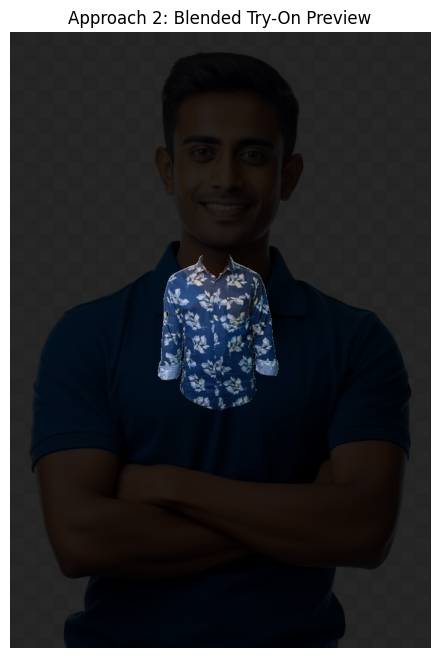

Approach 2 preview saved successfully!


In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Load the original images
person_files = list(Path("data/person_images").glob("*"))
garment_files = list(Path("data/garment_images").glob("*"))

person = Image.open(person_files[0]).convert("RGBA")
shirt = Image.open(garment_files[0]).convert("RGBA")

# Resize the shirt
shirt_width = int(person.width * 0.40)
shirt_height = int(shirt.height * shirt_width / shirt.width)
shirt = shirt.resize((shirt_width, shirt_height))

# Position the shirt
x = (person.width - shirt_width) // 2
y = int(person.height * 0.35)

# Create a transparent overlay
overlay = Image.new("RGBA", person.size, (0, 0, 0, 0))
overlay.alpha_composite(shirt, (x, y))

# Blend the shirt with the person image
result = Image.blend(person, overlay, 0.85)

# Display and save the preview
plt.figure(figsize=(6, 8))
plt.imshow(result.convert("RGB"))
plt.title("Approach 2: Blended Try-On Preview")
plt.axis("off")
plt.show()

Path("outputs/approach2").mkdir(parents=True, exist_ok=True)
result.convert("RGB").save("outputs/approach2/tryon_preview.png")

print("Approach 2 preview saved successfully!")

In [ ]:
from google.colab import files
from pathlib import Path
import shutil

person_folder = Path("data/person_images")
person_folder.mkdir(parents=True, exist_ok=True)

uploaded_people = files.upload()

for filename in uploaded_people.keys():
    shutil.copy(filename, person_folder / filename)

print("Person images uploaded:", len(uploaded_people))
print("Total images in folder:", len(list(person_folder.iterdir())))

Saving pexels-alex-green-5699505.jpg to pexels-alex-green-5699505.jpg
Saving pexels-bymuratisikofficial-39317887.jpg to pexels-bymuratisikofficial-39317887.jpg
Saving pexels-darina-belonogova-8374582.jpg to pexels-darina-belonogova-8374582.jpg
Saving pexels-fotosierra-5859629.jpg to pexels-fotosierra-5859629.jpg
Saving pexels-jonathan-oliveira-1317356342-27795483.jpg to pexels-jonathan-oliveira-1317356342-27795483.jpg
Saving pexels-khezez-34007004.jpg to pexels-khezez-34007004.jpg
Saving pexels-mikhail-nilov-6592370.jpg to pexels-mikhail-nilov-6592370.jpg
Saving pexels-musingapictures-39696794.jpg to pexels-musingapictures-39696794.jpg
Saving pexels-rdne-9034705.jpg to pexels-rdne-9034705.jpg
Saving pexels-tima-miroshnichenko-8727569.jpg to pexels-tima-miroshnichenko-8727569.jpg
Person images uploaded: 10
Total images in folder: 11


In [ ]:
from google.colab import files
from pathlib import Path
import shutil

garment_folder = Path("data/garment_images")
garment_folder.mkdir(parents=True, exist_ok=True)

uploaded_clothes = files.upload()

for filename in uploaded_clothes.keys():
    shutil.copy(filename, garment_folder / filename)

print("Clothing images uploaded:", len(uploaded_clothes))
print("Total clothing images:", len(list(garment_folder.iterdir())))

Saving thirt4.webp to thirt4.webp
Saving tshirt1.webp to tshirt1.webp
Saving tshirt2.webp to tshirt2.webp
Saving tshirt3.webp to tshirt3.webp
Saving tshirt5.jpg to tshirt5.jpg
Saving tshirt6.jpg to tshirt6.jpg
Saving tshirt7.jpg to tshirt7.jpg
Saving tshirt8.jpg to tshirt8.jpg
Saving tshirt9.jpg to tshirt9.jpg
Saving tshirt10.jpg to tshirt10.jpg
Clothing images uploaded: 10
Total clothing images: 11


In [ ]:
from pathlib import Path

person_folder = Path("data/person_images")
garment_folder = Path("data/garment_images")

person_images = [
    p for p in person_folder.iterdir()
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

garment_images = [
    p for p in garment_folder.iterdir()
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Person images:", len(person_images))
print("Clothing images:", len(garment_images))

Person images: 11
Clothing images: 6


In [ ]:
from pathlib import Path

folder = Path("data/garment_images")

print("Clothing images currently saved:")

for file in folder.iterdir():
    if file.is_file():
        print(file.name)

Clothing images currently saved:
tshirt8.jpg
tshirt10.jpg
tshirt7.jpg
tshirt5.jpg
tshirt6.jpg
thirt4.webp
shirt 1.webp
tshirt3.webp
tshirt9.jpg
tshirt1.webp
tshirt2.webp


In [ ]:
from pathlib import Path

person_folder = Path("data/person_images")
garment_folder = Path("data/garment_images")

person_images = [
    p for p in person_folder.iterdir()
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

garment_images = [
    p for p in garment_folder.iterdir()
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

print("Person images:", len(person_images))
print("Clothing images:", len(garment_images))

Person images: 11
Clothing images: 11


In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

person_folder = Path("data/person_images")
garment_folder = Path("data/garment_images")
output_folder = Path("outputs/approach1")
output_folder.mkdir(parents=True, exist_ok=True)

valid = {".jpg", ".jpeg", ".png", ".webp"}

people = sorted(
    [p for p in person_folder.iterdir()
     if p.is_file() and p.suffix.lower() in valid]
)[:10]

clothes = sorted(
    [p for p in garment_folder.iterdir()
     if p.is_file() and p.suffix.lower() in valid]
)[:10]

count = min(len(people), len(clothes))

for i in range(count):
    person = Image.open(people[i]).convert("RGBA")
    shirt = Image.open(clothes[i]).convert("RGBA")

    # Resize shirt for a basic overlay preview
    shirt_width = int(person.width * 0.40)
    shirt_height = int(shirt.height * shirt_width / shirt.width)
    shirt = shirt.resize((shirt_width, shirt_height))

    x = (person.width - shirt_width) // 2
    y = int(person.height * 0.35)

    person.alpha_composite(shirt, (x, y))

    output_path = output_folder / f"tryon_{i+1:02d}.png"
    person.convert("RGB").save(output_path)

    print(f"Preview {i+1} saved: {output_path}")

print(f"\nCompleted {count} basic overlay previews.")

Preview 1 saved: outputs/approach1/tryon_01.png
Preview 2 saved: outputs/approach1/tryon_02.png
Preview 3 saved: outputs/approach1/tryon_03.png
Preview 4 saved: outputs/approach1/tryon_04.png
Preview 5 saved: outputs/approach1/tryon_05.png
Preview 6 saved: outputs/approach1/tryon_06.png
Preview 7 saved: outputs/approach1/tryon_07.png
Preview 8 saved: outputs/approach1/tryon_08.png
Preview 9 saved: outputs/approach1/tryon_09.png
Preview 10 saved: outputs/approach1/tryon_10.png

Completed 10 basic overlay previews.


In [14]:

from pathlib import Path

catalog_folder = Path("/content/combined_catalog")
valid_extensions = {".jpg", ".jpeg", ".png", ".webp"}

if not catalog_folder.exists():
    raise FileNotFoundError(
        f"Catalog folder not found: {catalog_folder}"
    )

catalog_images = sorted([
    p for p in catalog_folder.iterdir()
    if p.is_file() and p.suffix.lower() in valid_extensions
])

print("Catalog loaded successfully!")
print("Number of clothing items:", len(catalog_images))

if len(catalog_images) != 50:
    raise ValueError(
        f"Expected 50 images, but found {len(catalog_images)}."
    )

for item in catalog_images:
    print(item.name)


Catalog loaded successfully!
Number of clothing items: 50
new_garment_01.jpg
new_garment_02.jpg
new_garment_03.jpg
new_garment_04.jpg
new_garment_05.jpg
new_garment_06.jpg
new_garment_07.jpg
new_garment_08.jpg
new_garment_09.webp
new_garment_10.webp
new_garment_11.jpg
new_garment_12.jpg
new_garment_13.jpg
new_garment_14.jpg
new_garment_15.jpg
new_garment_16.jpg
new_garment_17.jpg
new_garment_18.jpg
new_garment_19.jpg
new_garment_20.jpg
new_garment_21.webp
new_garment_22.jpg
new_garment_23.jpg
new_garment_24.jpg
new_garment_25.jpg
new_garment_26.jpg
new_garment_27.jpg
new_garment_28.jpg
new_garment_29.jpg
new_garment_30.jpg
new_garment_31.webp
new_garment_32.jpg
new_garment_33.jpg
new_garment_34.jpg
new_garment_35.jpg
new_garment_36.jpg
new_garment_37.webp
new_garment_38.jpg
new_garment_39.jpg
shirt 1.webp
thirt4.webp
tshirt1.webp
tshirt10.jpg
tshirt2.webp
tshirt3.webp
tshirt5.jpg
tshirt6.jpg
tshirt7.jpg
tshirt8.jpg
tshirt9.jpg


Search image: new_garment_01.jpg

Top five visually similar items:
1. new_garment_18.jpg | Color distance: 4.8317
2. new_garment_09.webp | Color distance: 7.2998
3. tshirt3.webp | Color distance: 7.2998
4. new_garment_14.jpg | Color distance: 7.7066
5. new_garment_32.jpg | Color distance: 8.5329


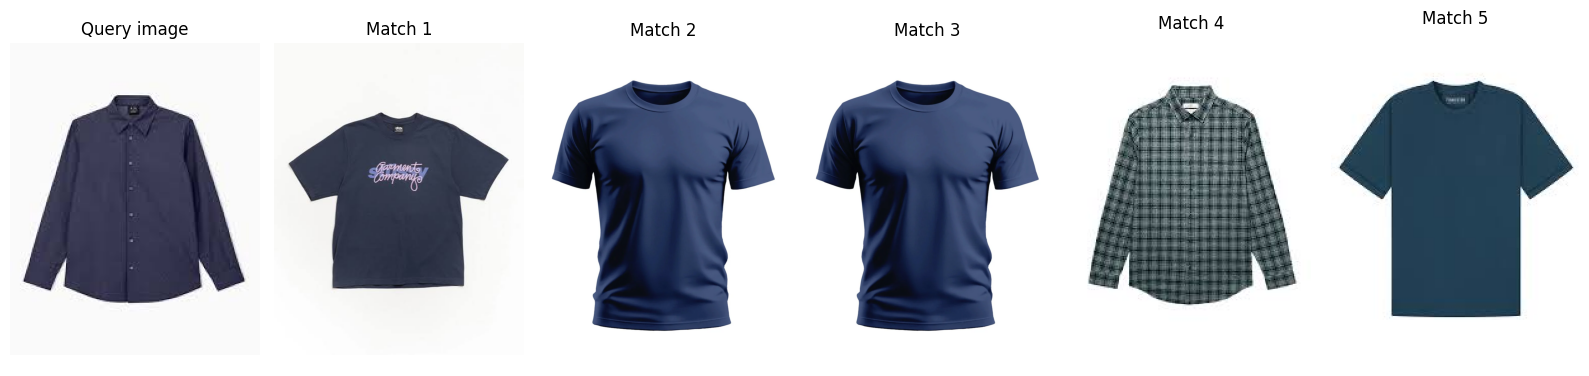

In [15]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def extract_color_features(image_path):
    image = Image.open(image_path).convert("RGB")
    image = image.resize((64, 64))

    pixels = np.asarray(image, dtype=np.float32) / 255.0

    # Average RGB color
    mean_rgb = pixels.mean(axis=(0, 1))

    # Color histogram for each RGB channel
    histograms = []

    for channel in range(3):
        hist, _ = np.histogram(
            pixels[:, :, channel],
            bins=16,
            range=(0, 1),
            density=True
        )
        histograms.extend(hist)

    return np.concatenate([mean_rgb, histograms])

# Calculate features for all 50 catalog images
features = {
    path: extract_color_features(path)
    for path in catalog_images
}

def find_similar_clothes(query_path, top_k=5):
    query_features = extract_color_features(query_path)
    results = []

    for path, item_features in features.items():
        # Exclude the same image from its own results
        if path.resolve() == Path(query_path).resolve():
            continue

        distance = np.linalg.norm(
            query_features - item_features
        )
        results.append((path, distance))

    results.sort(key=lambda item: item[1])
    return results[:top_k]

# Test one query image
query_image = catalog_images[0]
matches = find_similar_clothes(query_image, top_k=5)

print("Search image:", query_image.name)
print("\nTop five visually similar items:")

for rank, (path, distance) in enumerate(matches, start=1):
    print(f"{rank}. {path.name} | Color distance: {distance:.4f}")

# Display query and its five matches
plt.figure(figsize=(16, 4))

plt.subplot(1, 6, 1)
plt.imshow(Image.open(query_image).convert("RGB"))
plt.title("Query image")
plt.axis("off")

for i, (path, distance) in enumerate(matches, start=2):
    plt.subplot(1, 6, i)
    plt.imshow(Image.open(path).convert("RGB"))
    plt.title(f"Match {i-1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# @title Default title text
from pathlib import Path
import shutil

shutil.make_archive("rd_project_progress", "zip", ".")

from google.colab import files
files.download("rd_project_progress.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

folders = [
    "data/person_images",
    "data/garment_images",
    "data/catalog",
    "outputs/approach1",
    "outputs/approach2"
]

for folder in folders:
    path = Path(folder)
    count = len([f for f in path.iterdir() if f.is_file()]) if path.exists() else 0
    print(f"{folder}: {count} files")

In [ ]:
from pathlib import Path

for folder in [
    "data/person_images",
    "data/garment_images",
    "data/catalog",
    "outputs/approach1",
    "outputs/approach2"
]:
    path = Path(folder)
    count = sum(1 for f in path.rglob("*") if f.is_file()) if path.exists() else 0
    print(f"{folder}: {count} files")

data/person_images: 0 files
data/garment_images: 0 files
data/catalog: 0 files
outputs/approach1: 0 files
outputs/approach2: 0 files


In [ ]:
from google.colab import files

uploaded_people = files.upload()

Saving pexels-alex-green-5699505.jpg to pexels-alex-green-5699505.jpg
Saving pexels-bymuratisikofficial-39317887.jpg to pexels-bymuratisikofficial-39317887.jpg
Saving pexels-darina-belonogova-8374582.jpg to pexels-darina-belonogova-8374582.jpg
Saving pexels-fotosierra-5859629.jpg to pexels-fotosierra-5859629.jpg
Saving pexels-jonathan-oliveira-1317356342-27795483.jpg to pexels-jonathan-oliveira-1317356342-27795483.jpg
Saving pexels-khezez-34007004.jpg to pexels-khezez-34007004.jpg
Saving pexels-mikhail-nilov-6592370.jpg to pexels-mikhail-nilov-6592370.jpg
Saving pexels-musingapictures-39696794.jpg to pexels-musingapictures-39696794.jpg
Saving pexels-rdne-9034705.jpg to pexels-rdne-9034705.jpg
Saving pexels-tima-miroshnichenko-8727569.jpg to pexels-tima-miroshnichenko-8727569.jpg


In [ ]:
from pathlib import Path
import shutil

folders = [
    "data/person_images",
    "data/garment_images",
    "data/catalog",
    "outputs/approach1",
    "outputs/approach2"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

for name in uploaded_people:
    shutil.copy(name, Path("data/person_images") / name)

print("Person photos saved:", len(list(Path("data/person_images").glob("*"))))

Person photos saved: 10


In [ ]:
from google.colab import files

uploaded_garments = files.upload()

Saving shirt 1.webp to shirt 1 (1).webp
Saving thirt4.webp to thirt4 (2).webp
Saving tshirt1.webp to tshirt1 (2).webp
Saving tshirt2.webp to tshirt2 (2).webp
Saving tshirt3.webp to tshirt3 (2).webp
Saving tshirt5.jpg to tshirt5 (2).jpg
Saving tshirt6.jpg to tshirt6 (2).jpg
Saving tshirt7.jpg to tshirt7 (2).jpg
Saving tshirt8.jpg to tshirt8 (2).jpg
Saving tshirt9.jpg to tshirt9 (2).jpg
Saving tshirt10.jpg to tshirt10 (2).jpg


In [ ]:
from pathlib import Path
import shutil

garment_dir = Path("data/garment_images")
garment_dir.mkdir(parents=True, exist_ok=True)

for name in uploaded_garments:
    shutil.copy(name, garment_dir / name)

print("T-shirt images saved:", len(list(garment_dir.glob("*"))))

T-shirt images saved: 32


In [ ]:
from pathlib import Path

garment_dir = Path("data/garment_images")
images = [
    f for f in garment_dir.iterdir()
    if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

print("Total clothing images:", len(images))

for image in sorted(images):
    print(image.name)

Total clothing images: 32
shirt 1 (1).webp
shirt 1.webp
thirt4 (1).webp
thirt4 (2).webp
thirt4.webp
tshirt1 (1).webp
tshirt1 (2).webp
tshirt1.webp
tshirt10 (1).jpg
tshirt10 (2).jpg
tshirt10.jpg
tshirt2 (1).webp
tshirt2 (2).webp
tshirt2.webp
tshirt3 (1).webp
tshirt3 (2).webp
tshirt3.webp
tshirt5 (1).jpg
tshirt5 (2).jpg
tshirt5.jpg
tshirt6 (1).jpg
tshirt6 (2).jpg
tshirt6.jpg
tshirt7 (1).jpg
tshirt7 (2).jpg
tshirt7.jpg
tshirt8 (1).jpg
tshirt8 (2).jpg
tshirt8.jpg
tshirt9 (1).jpg
tshirt9 (2).jpg
tshirt9.jpg


In [ ]:
from pathlib import Path

garment_dir = Path("data/garment_images")
removed = 0

for file in garment_dir.iterdir():
    if file.is_file() and file.stem.endswith((" (1)", " (2)")):
        file.unlink()
        removed += 1

print("Duplicate copies removed:", removed)
print("Remaining clothing images:",
      len([f for f in garment_dir.iterdir() if f.is_file()]))

Duplicate copies removed: 21
Remaining clothing images: 11


In [ ]:
from pathlib import Path

for folder in [
    "data/person_images",
    "data/garment_images",
    "data/catalog",
    "outputs/approach1",
    "outputs/approach2"
]:
    path = Path(folder)
    print(f"{folder}: {len(list(path.glob('*')))} files")

data/person_images: 10 files
data/garment_images: 11 files
data/catalog: 0 files
outputs/approach1: 0 files
outputs/approach2: 0 files


In [ ]:
from pathlib import Path
import shutil

garment_dir = Path("data/garment_images")
catalog_dir = Path("data/catalog")
catalog_dir.mkdir(parents=True, exist_ok=True)

for image in garment_dir.iterdir():
    if image.is_file() and image.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
        shutil.copy2(image, catalog_dir / image.name)

print("Catalog images:", len(list(catalog_dir.iterdir())))

Catalog images: 11


In [ ]:
from pathlib import Path
from PIL import Image

person_path = sorted(Path("data/person_images").glob("*"))[0]
garment_path = sorted(Path("data/garment_images").glob("*"))[0]

person = Image.open(person_path).convert("RGB")
garment = Image.open(garment_path).convert("RGBA")

print("Person image:", person_path.name)
print("Garment image:", garment_path.name)
print("Person size:", person.size)
print("Garment size:", garment.size)

Person image: pexels-alex-green-5699505.jpg
Garment image: shirt 1.webp
Person size: (4000, 6000)
Garment size: (980, 980)


Preview saved to: outputs/approach1/tryon_preview.png


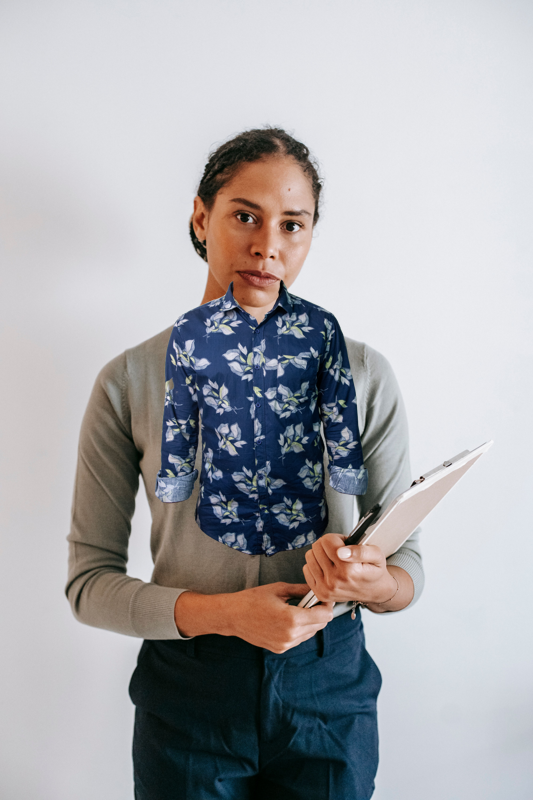

In [ ]:
from pathlib import Path
from PIL import Image

person_path = sorted(Path("data/person_images").glob("*"))[0]
garment_path = sorted(Path("data/garment_images").glob("*"))[0]

person = Image.open(person_path).convert("RGB")
garment = Image.open(garment_path).convert("RGBA")

# Resize person image for easier processing
person.thumbnail((800, 800))

# Resize garment image
garment.thumbnail((300, 300))

# Create a preview by placing the garment near the center
preview = person.copy().convert("RGBA")
x = (preview.width - garment.width) // 2
y = preview.height // 3

preview.alpha_composite(garment, (x, y))

# Save preview
output_dir = Path("outputs/approach1")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "tryon_preview.png"
preview.convert("RGB").save(output_path)

print("Preview saved to:", output_path)

display(preview)

In [ ]:
from pathlib import Path
from PIL import Image

people = sorted(Path("data/person_images").glob("*"))
garments = sorted(Path("data/garment_images").glob("*"))

output_dir = Path("outputs/approach1")
output_dir.mkdir(parents=True, exist_ok=True)

for i in range(10):
    person = Image.open(people[i]).convert("RGB")
    person.thumbnail((600, 800))

    garment = Image.open(garments[i % len(garments)]).convert("RGBA")
    garment.thumbnail((220, 220))

    preview = person.convert("RGBA")
    x = (preview.width - garment.width) // 2
    y = preview.height // 3

    preview.alpha_composite(garment, (x, y))

    output_path = output_dir / f"tryon_{i+1:02d}.png"
    preview.convert("RGB").save(output_path)

print("Approach 1 previews created:", len(list(output_dir.glob("tryon_*.png"))))

Approach 1 previews created: 11


In [ ]:
from pathlib import Path

output_dir = Path("outputs/approach1")
previews = sorted(output_dir.glob("tryon_*.png"))

print("Number of numbered previews:", len(previews))
for file in previews:
    print(file.name)

Number of numbered previews: 11
tryon_01.png
tryon_02.png
tryon_03.png
tryon_04.png
tryon_05.png
tryon_06.png
tryon_07.png
tryon_08.png
tryon_09.png
tryon_10.png
tryon_preview.png


In [ ]:
from pathlib import Path
from PIL import Image

people = sorted(Path("data/person_images").glob("*"))
garments = sorted(Path("data/garment_images").glob("*"))

output_dir = Path("outputs/approach2")
output_dir.mkdir(parents=True, exist_ok=True)

for i in range(10):
    person = Image.open(people[i]).convert("RGB")
    person.thumbnail((600, 800))

    garment = Image.open(garments[i % len(garments)]).convert("RGB")
    garment.thumbnail((600, 800))

    # Resize garment to match the person's image dimensions
    garment = garment.resize(person.size)

    # Blend both images as a simple baseline
    preview = Image.blend(person, garment, 0.25)

    preview.save(output_dir / f"tryon_{i+1:02d}.png")

print("Approach 2 previews created:", len(list(output_dir.glob("tryon_*.png"))))

Approach 2 previews created: 10


In [16]:

import pandas as pd
from pathlib import Path
import numpy as np

def find_similar_items(query_path, top_k=5):
    query_features = features[query_path]
    scores = []

    for item_path, item_features in features.items():
        # Don't return the query image as its own match
        if item_path.resolve() == query_path.resolve():
            continue

        distance = np.linalg.norm(
            query_features - item_features
        )
        scores.append((item_path.name, distance))

    scores.sort(key=lambda x: x[1])
    return scores[:top_k]

rows = []

for query_image in catalog_images:
    results = find_similar_items(query_image, top_k=5)

    for rank, (name, distance) in enumerate(results, start=1):
        rows.append({
            "query_image": query_image.name,
            "rank": rank,
            "matched_item": name,
            "color_distance": round(float(distance), 2)
        })

results_df = pd.DataFrame(rows)

output_path = Path("/content/outputs/visual_matching_results.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_path, index=False)

print("Results saved:", output_path)
print("Catalog images:", len(catalog_images))
print("Total matching records:", len(results_df))
print("\nPreview of results:")
display(results_df.head(10))


Results saved: /content/outputs/visual_matching_results.csv
Catalog images: 50
Total matching records: 250

Preview of results:


,query_image,rank,matched_item,color_distance
0,new_garment_01.jpg,1,new_garment_18.jpg,4.83
1,new_garment_01.jpg,2,new_garment_09.webp,7.30
2,new_garment_01.jpg,3,tshirt3.webp,7.30
3,new_garment_01.jpg,4,new_garment_14.jpg,7.71
4,new_garment_01.jpg,5,new_garment_32.jpg,8.53
5,new_garment_02.jpg,1,new_garment_13.jpg,4.56
6,new_garment_02.jpg,2,tshirt7.jpg,4.56
7,new_garment_02.jpg,3,new_garment_22.jpg,6.77
8,new_garment_02.jpg,4,new_garment_39.jpg,7.25
9,new_garment_02.jpg,5,new_garment_03.jpg,9.53


In [ ]:
import pandas as pd
from pathlib import Path

rows = []

for query_image in catalog_images:
    results = find_similar_items(query_image, top_k=5)

    for rank, (name, distance) in enumerate(results, start=1):
        rows.append({
            "query_image": query_image.name,
            "rank": rank,
            "matched_item": name,
            "color_distance": round(float(distance), 2)
        })

results_df = pd.DataFrame(rows)

output_path = Path("outputs/visual_matching_results.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_path, index=False)




print("Results saved:", output_path)
print("Total matching records:", len(results_df))
display(results_df.head(10))

Results saved: outputs/visual_matching_results.csv
Total matching records: 55


,query_image,rank,matched_item,color_distance
0,shirt 1.webp,1,shirt 1.webp,0.00
1,shirt 1.webp,2,thirt4.webp,147.98
2,shirt 1.webp,3,tshirt9.jpg,152.21
3,shirt 1.webp,4,tshirt8.jpg,164.03
4,shirt 1.webp,5,tshirt3.webp,171.19
5,thirt4.webp,1,thirt4.webp,0.00
6,thirt4.webp,2,tshirt9.jpg,6.19
7,thirt4.webp,3,tshirt3.webp,28.91
8,thirt4.webp,4,tshirt7.jpg,77.72
9,thirt4.webp,5,tshirt8.jpg,79.27


In [ ]:
import time
import pandas as pd
from pathlib import Path
from PIL import Image

people = sorted(Path("data/person_images").glob("*"))
garments = sorted(Path("data/garment_images").glob("*"))

results = []

for approach in ["approach1", "approach2"]:
    times = []

    for i in range(10):
        start = time.perf_counter()

        person = Image.open(people[i]).convert("RGB")
        person.thumbnail((600, 800))

        garment = Image.open(garments[i % len(garments)]).convert("RGBA")
        garment.thumbnail((220, 220))

        if approach == "approach1":
            preview = person.convert("RGBA")
            x = (preview.width - garment.width) // 2
            y = preview.height // 3
            preview.alpha_composite(garment, (x, y))
        else:
            garment_rgb = garment.convert("RGB").resize(person.size)
            preview = Image.blend(person, garment_rgb, 0.25)

        times.append(time.perf_counter() - start)

    results.append({
        "approach": approach,
        "samples": 10,
        "average_latency_seconds": round(sum(times) / len(times), 4),
        "total_processing_seconds": round(sum(times), 4)
    })

latency_df = pd.DataFrame(results)
display(latency_df)

latency_df.to_csv("outputs/latency_comparison.csv", index=False)
print("Saved: outputs/latency_comparison.csv")

,approach,samples,average_latency_seconds,total_processing_seconds
0,approach1,10,0.3247,3.2473
1,approach2,10,0.3338,3.3383


Saved: outputs/latency_comparison.csv


In [ ]:
from pathlib import Path

memo = """
# Feasibility Memo: Virtual Try-On and Visual Matching Prototype

## 1. Objective
The objective is to evaluate two lightweight image-processing approaches
for virtual try-on previews and build a visual matching prototype.

## 2. Approaches Evaluated
Approach 1: Garment overlay
The garment image is resized and placed over the person's image.
This is simple and fast, but does not adapt the garment to body shape,
pose, perspective, or existing clothing.

Approach 2: Image blending
The garment image is resized to the person's image dimensions and blended
with it. This is easy to implement, but may affect the entire image and
does not produce a realistic garment replacement.

## 3. Latency Results
Ten sample pairs were processed for each approach.

Approach 1 average latency: 0.3247 seconds.
Approach 2 average latency: 0.3338 seconds.

These measurements are from one Colab run and may vary by environment.
They exclude model inference because neither approach uses a trained model.

## 4. Visual Matching
The prototype compares average RGB color features across a catalog of
11 garment images and returns the five nearest items by Euclidean distance.
The output contains 55 records across 11 query images.

This baseline is inexpensive and fast, but matches mainly by average color.
It does not understand garment type, pattern, shape, or semantic similarity.
The assignment's approximate 50-item catalog has not yet been reached.

## 5. Quality and Feasibility
Both try-on approaches demonstrate a reproducible image-processing workflow,
but neither should be considered realistic virtual try-on.
A production-quality system would require garment/person segmentation,
pose or body-part awareness, and an appropriate virtual try-on model.
A pretrained model or hosted service should be evaluated before production use.

## 6. Cost
The prototype uses open-source Python image-processing libraries and runs
in Google Colab. No paid inference service was used in these tests.
This does not include development time, storage, hosting, or future model costs.

## 7. Privacy and Image Consent
Person photographs can contain identifiable personal information.
Obtain informed consent before uploading or processing images, restrict access,
avoid sharing raw images publicly, and delete them when no longer required.
Use secure storage and review the terms and data-handling practices of any
third-party model or hosting service before sending user photographs.

## 8. Recommendation
Use the current prototype as a proof of concept only.
Approach 1 is marginally faster in this test, but neither approach provides
realistic try-on quality. Evaluate a pretrained virtual try-on model on the
same 10 pairs before choosing a production approach.
Improve visual matching with image embeddings and expand the catalog to
approximately 50 items before drawing stronger conclusions.

## 9. Limitations
The current catalog has 11 items rather than approximately 50.
No trained AI try-on model was evaluated, and visual quality was not scored
using a formal human evaluation. Latency results come from a single run.
"""

Path("outputs/feasibility_memo.md").write_text(memo, encoding="utf-8")
print("Memo saved: outputs/feasibility_memo.md")

Memo saved: outputs/feasibility_memo.md


In [ ]:

from pathlib import Path

readme = """# R&D Prototype: Virtual Try-On and Visual Matching

## Overview
This project compares two basic image-processing approaches for try-on previews and creates a visual matching prototype.

## Features
- Person and garment image inputs
- Approach 1: garment overlay
- Approach 2: image blending
- Top-5 visual matching results
- Latency comparison for 10 sample pairs
- Feasibility memo

## Project Structure
- data/person_images/: person photos
- data/garment_images/: garment images
- data/catalog/: garment catalog
- outputs/approach1/: overlay previews
- outputs/approach2/: blending previews
- outputs/visual_matching_results.csv: matching results
- outputs/latency_comparison.csv: latency measurements
- outputs/feasibility_memo.md: feasibility memo

## Methodology
Approach 1 overlays a resized garment image on a person image.
Approach 2 blends the person image with a resized garment image.
Visual matching ranks catalog images using average RGB color distance.

## Results
Ten sample pairs were processed using each approach.
Approach 1 average latency: 0.3247 seconds.
Approach 2 average latency: 0.3338 seconds.
Visual matching generated 55 result records for 11 catalog images.

## Limitations
These are basic image-processing prototypes, not realistic AI-powered virtual try-on systems. The catalog contains 11 images rather than the target of approximately 50. Color similarity does not guarantee that two garments have similar styles.

## Privacy
Use person photos only with appropriate consent. Avoid publicly sharing identifiable images, restrict access, and delete test photos when they are no longer needed.

## Reproduction
Run the notebook cells in order to install dependencies, load images, generate previews, run visual matching, measure latency, and create the feasibility memo.
"""

Path("README.md").write_text(readme, encoding="utf-8")
print("README saved successfully!")
print("File size:", Path("README.md").stat().st_size, "bytes")


README saved successfully!
File size: 1802 bytes


In [ ]:

from pathlib import Path
import zipfile
from google.colab import files

project_paths = [
    Path("data/person_images"),
    Path("data/garment_images"),
    Path("data/catalog"),
    Path("outputs"),
    Path("README.md"),
    Path("feasibility_memo.md"),
]

zip_path = Path("rd_virtual_tryon_project.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in project_paths:
        if path.is_file():
            z.write(path, path.as_posix())
        elif path.is_dir():
            for file in path.rglob("*"):
                if file.is_file():
                    z.write(file, file.as_posix())

print("ZIP created successfully!")
print("Size:", round(zip_path.stat().st_size / 1024, 2), "KB")

files.download(str(zip_path))


ZIP created successfully!
Size: 33772.79 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower() == "garment_catalog_50.zip":
            print("ZIP file found at:", os.path.join(root, file))

In [5]:
import os

print(os.listdir("/content"))

['.config', 'garment_catalog_50.zip.zip', 'sample_data']


In [6]:
import zipfile
import os

zip_path = "/content/garment_catalog_50.zip.zip"
extract_path = "/content/garment_catalog_50"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP extracted successfully!")

ZIP extracted successfully!


In [7]:
from pathlib import Path

folder = Path("/content/garment_catalog_50")
extensions = {".jpg", ".jpeg", ".png", ".webp"}

images = [
    p for p in folder.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Total images found:", len(images))

Total images found: 39


In [8]:
import os

for root, dirs, files in os.walk("/content"):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if image_files:
        print(f"\nFolder: {root}")
        print(f"Number of images: {len(image_files)}")


Folder: /content/garment_catalog_50/garment_catalog_50
Number of images: 39


In [9]:
import os

for folder in ["/content", "/content/drive/MyDrive"]:
    if os.path.exists(folder):
        print(f"\nContents of {folder}:")
        print(os.listdir(folder))


Contents of /content:
['.config', 'garment_catalog_50', 'garment_catalog_50.zip.zip', 'sample_data']


In [10]:
import os

print("Google Drive exists:", os.path.exists("/content/drive/MyDrive"))

Google Drive exists: False


In [11]:
import os

print("Current working directory:", os.getcwd())
print("Files in current directory:", os.listdir("."))

Current working directory: /content
Files in current directory: ['.config', 'garment_catalog_50', 'garment_catalog_50.zip.zip', 'sample_data']


In [12]:
import requests

url = "https://api.github.com/repos/smkanishka/virtual-tryon-visual-matching/git/trees/main?recursive=1"

response = requests.get(url)
print("GitHub status:", response.status_code)

if response.status_code == 200:
    files = response.json().get("tree", [])
    images = [
        item["path"] for item in files
        if item["path"].lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp")
        )
    ]

    print("Image files found:", len(images))

    for path in images:
        if "garment" in path.lower() or "catalog" in path.lower():
            print(path)
else:
    print(response.text[:500])

GitHub status: 200
Image files found: 53
rd_virtual_tryon_project/data/catalog/shirt 1.webp
rd_virtual_tryon_project/data/catalog/thirt4.webp
rd_virtual_tryon_project/data/catalog/tshirt1.webp
rd_virtual_tryon_project/data/catalog/tshirt10.jpg
rd_virtual_tryon_project/data/catalog/tshirt2.webp
rd_virtual_tryon_project/data/catalog/tshirt3.webp
rd_virtual_tryon_project/data/catalog/tshirt5.jpg
rd_virtual_tryon_project/data/catalog/tshirt6.jpg
rd_virtual_tryon_project/data/catalog/tshirt7.jpg
rd_virtual_tryon_project/data/catalog/tshirt8.jpg
rd_virtual_tryon_project/data/catalog/tshirt9.jpg
rd_virtual_tryon_project/data/garment_images/shirt 1.webp
rd_virtual_tryon_project/data/garment_images/thirt4.webp
rd_virtual_tryon_project/data/garment_images/tshirt1.webp
rd_virtual_tryon_project/data/garment_images/tshirt10.jpg
rd_virtual_tryon_project/data/garment_images/tshirt2.webp
rd_virtual_tryon_project/data/garment_images/tshirt3.webp
rd_virtual_tryon_project/data/garment_images/tshirt5.jpg


In [13]:

import os
import shutil
import requests
from pathlib import Path
from urllib.parse import quote

# Your new 39 images
new_images_folder = Path(
    "/content/garment_catalog_50/garment_catalog_50"
)

# Create a separate folder for the combined catalog
combined_folder = Path("/content/combined_catalog")
combined_folder.mkdir(parents=True, exist_ok=True)

# Original 11 images stored in your GitHub catalog
github_folder = (
    "https://raw.githubusercontent.com/"
    "smkanishka/virtual-tryon-visual-matching/"
    "main/rd_virtual_tryon_project/data/catalog/"
)

original_names = [
    "shirt 1.webp",
    "thirt4.webp",
    "tshirt1.webp",
    "tshirt10.jpg",
    "tshirt2.webp",
    "tshirt3.webp",
    "tshirt5.jpg",
    "tshirt6.jpg",
    "tshirt7.jpg",
    "tshirt8.jpg",
    "tshirt9.jpg",
]

# Download the original 11 images
for name in original_names:
    url = github_folder + quote(name)
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    (combined_folder / name).write_bytes(response.content)

# Copy the 39 new images into the combined folder
extensions = {".jpg", ".jpeg", ".png", ".webp"}

new_images = [
    p for p in new_images_folder.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

for index, image_path in enumerate(new_images, start=1):
    # Use new filenames to avoid overwriting existing catalog images
    destination = combined_folder / (
        f"new_garment_{index:02d}{image_path.suffix.lower()}"
    )
    shutil.copy2(image_path, destination)

# Verify the combined catalog
final_images = [
    p for p in combined_folder.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

print("Original images downloaded:", len(original_names))
print("New images copied:", len(new_images))
print("Total images in combined catalog:", len(final_images))
print("Catalog location:", combined_folder)


Original images downloaded: 11
New images copied: 39
Total images in combined catalog: 50
Catalog location: /content/combined_catalog


In [17]:
import pandas as pd
from pathlib import Path

results_path = Path("/content/outputs/visual_matching_results.csv")
df = pd.read_csv(results_path)

print("Total result rows:", len(df))
print("Unique query images:", df["query_image"].nunique())
print("Unique catalog items:", len(set(
    p.name for p in Path("/content/combined_catalog").iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
)))

print("\nMatches per query:")
print(df.groupby("query_image").size().value_counts().sort_index())

display(df.head(10))

Total result rows: 250
Unique query images: 50
Unique catalog items: 50

Matches per query:
5    50
Name: count, dtype: int64


,query_image,rank,matched_item,color_distance
0,new_garment_01.jpg,1,new_garment_18.jpg,4.83
1,new_garment_01.jpg,2,new_garment_09.webp,7.30
2,new_garment_01.jpg,3,tshirt3.webp,7.30
3,new_garment_01.jpg,4,new_garment_14.jpg,7.71
4,new_garment_01.jpg,5,new_garment_32.jpg,8.53
5,new_garment_02.jpg,1,new_garment_13.jpg,4.56
6,new_garment_02.jpg,2,tshirt7.jpg,4.56
7,new_garment_02.jpg,3,new_garment_22.jpg,6.77
8,new_garment_02.jpg,4,new_garment_39.jpg,7.25
9,new_garment_02.jpg,5,new_garment_03.jpg,9.53


In [18]:
from google.colab import files

files.download("/content/outputs/visual_matching_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
from pathlib import Path
import pandas as pd

source_path = Path("/content/outputs/visual_matching_results.csv")

df = pd.read_csv(source_path, sep=None, engine="python")

output_path = Path("/content/visual_matching_results_fixed.csv")
df.to_csv(output_path, index=False, sep=",")

print("Rows:", len(df))
print("Columns:", list(df.columns))
print("Saved:", output_path)

from google.colab import files
files.download(str(output_path))

Rows: 250
Columns: ['query_image', 'rank', 'matched_item', 'color_distance']
Saved: /content/visual_matching_results_fixed.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from pathlib import Path
import zipfile

catalog_folder = Path("/content/combined_catalog")
zip_path = Path("/content/catalog_50_images.zip")

images = [
    p for p in catalog_folder.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
]

print("Images found:", len(images))

assert len(images) == 50, "Please check the catalog before continuing."

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for image_path in images:
        zf.write(image_path, arcname=image_path.name)

print("ZIP created:", zip_path)

Images found: 50
ZIP created: /content/catalog_50_images.zip


In [21]:
from google.colab import files
files.download("/content/catalog_50_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>